In [108]:
from typing import TypedDict, Literal

class Ingredient(TypedDict):
    name: str
    amount: float
    unit: str
    flavour: Literal[
        'acidity', 'salt', 'spice', 'bitter', 
        'creamy', 'sweet', 'none', 'aromatic'
        ]
    type: Literal[
        'starches', 'sugars', 'salts', 'fats', 
        'seeds_nuts_dried_fruits', 'binders', 
        'produce', 'spices', 'sugars', 'liquids'
        ]
    ingredients: list[Ingredient]
    cons: Literal["SOLID", "LIQUID"]


class Recipe(TypedDict):
    name: str
    servings: int
    ingredients: list[Ingredient]
    source: str

In [109]:
%pip install pandas

import pprint
import json
from pathlib import Path
import pandas as pd
from typing import Any, cast


def load_json_file(path: str | Path) -> list[Recipe]:
    json_path = Path(path)

    if not json_path.exists():
        raise FileNotFoundError(f"File not found: {json_path.resolve()}")

    text = json_path.read_text(encoding="utf-8").strip()
    if not text:
        raise ValueError(f"JSON file is empty: {json_path.resolve()}")

    try:
        data: Any = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(
            f"Invalid JSON in {json_path.resolve()} "
            f"at line {error.lineno}, column {error.colno}"
        ) from error

    if isinstance(data, list):
        return cast(list[Recipe], data)

    if isinstance(data, dict) and isinstance(data.get("results"), list):
        return cast(list[Recipe], data["results"])

    raise ValueError(
        f"Expected a JSON list or an object containing a 'results' list: "
        f"{json_path.resolve()}"
    )


def find_and_replace_recipe_properties(
    inspiring_set: list[Recipe],
    replacement_data: pd.DataFrame,
    target_properties: list[str] | None = None,
    reference_column: str = "ingredient",
) -> list[Recipe]:
    properties = target_properties or ["flavour", "type", "is_indonesian"]

    if reference_column not in replacement_data.columns:
        raise KeyError(
            f"Column {reference_column!r} not found in metadata. "
            f"Available columns: {list(replacement_data.columns)}"
        )

    for recipe in inspiring_set:
        for ingredient in recipe["ingredients"]:
            ingredient_name = ingredient.get("name")
            if not ingredient_name:
                continue

            matching_rows = replacement_data[
                replacement_data[reference_column] == ingredient_name
            ]

            if matching_rows.empty:
                continue

            row = matching_rows.iloc[0]
            for prop in properties:
                if prop in matching_rows.columns and pd.notna(row[prop]):
                    value = row[prop]
                    ingredient[prop] = value.item() if hasattr(value, 'item') else value

    return inspiring_set


ingredient_metadata = pd.read_csv("data/ingredient_classification.csv")

with open("data/inspiring_set.json", "w", encoding="utf-8") as f:
    json.dump(
        inspiring_set,
        f,
        ensure_ascii=False,
        indent=4,
        default=json_default,
    )


def json_default(value):
    if hasattr(value, "item"):
        return value.item()
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")





Note: you may need to restart the kernel to use updated packages.


In [110]:
#normalizing data: adding sources & managing tsp/tbsp cases 

def norm_data(recipes:list[Recipe]) -> list[Recipe]:
    for recipe in recipes:
        for i in recipe["ingredients"]:
            i["source"]=recipe["name"]
            if i["unit"] in ["tsp", "tsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*5.0

            elif i["unit"] in ["Tbsp", "Tbsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*15.0
            elif i["unit"]=="pinch":
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*0.5
            elif i["unit"] in ["stick", "sticks"]:
                i["unit"]="g"
                i["amount"]=i["amount"]*113
            elif i["name"] in ["eggs", "egg", "egg yolk", "egg yolks"]:
                if i["unit"]=="large":
                    i["amount"] = i["amount"] * 55.0
                else:
                    i["amount"] = i["amount"] * 50.0
                i["unit"]="g"
            elif i["unit"] in ["cup", "cups"]:
                if i["cons"] == "LIQUID":
                        i["amount"] = i["amount"] * 240.0
                        i["unit"] = "ml"
                else:
                    i["amount"] = i["amount"] * 130.0
                    i["unit"] = "g"
    return recipes

clist=norm_data(inspring_set)

In [111]:
#creating a list of all indonesian ingredients adding their source

i_ings=[]

for recipe in inspring_set:
    for ing in recipe["ingredients"]:
        if ing["name"] not in ["ice", "water", "sugar", "food colouring"]:
            i_ings.append({**ing, "source": recipe["name"]})

i_names= {ing["name"] for ing in i_ings}

In [112]:
#Initialisation of the population

import random

pop_size=30

population = random.choices(clist, k=pop_size)

In [113]:
#evaluating recipes based on:
#1 how many indonesian drinks they get inspiration from
#2 no more than 12 ingredients (I saw that the average in the original list of Western cookies is 9.74)
# any very important ingredients have no less than 50 g
#no ingredient has less than 5 g
"""
#TODO


- make it create novel recipes
    - the ingredient
- cookies need to tast good
  - sweet
  - sour
  - bitter
  - salty
- correct structure:
    - not too much flour, not too much sugar, not too much fat
        - fat
        - beverages
        - dryness starches
    - not too much liquid, not too much eggs
"""

def has_correct_ingredient_ratios(recipe: Recipe, ratios: list[tuple[str, float, float]], key: str) -> float:
    targets_reached: int = 0;

    for ingredient_type, min_ratio, max_ratio in ratios:
        
        # see the total amount of the ingredient per type
        total_amount = sum(
            ing["amount"] for ing in recipe["ingredients"] if ing[key] == ingredient_type
        )

        # total mass of the recipe
        total_recipe_amount = sum(ing["amount"] for ing in recipe["ingredients"])
        ratio = total_amount / total_recipe_amount if total_recipe_amount > 0 else 0

        if (min_ratio <= ratio <= max_ratio):
            targets_reached += 1
    ratio = targets_reached / len(ratios) if len(ratios) > 0 else 0
    print("Ratio:", ratio, "Targets reached:", targets_reached, "Total ratios:", len(ratios))
    return ratio  # Return the proportion of targets reached


def evaluate_recipes(recipes: list[Recipe]) -> None:

    texture_ratios: list[tuple[str, float, float]] = [
            ("starches", 0.2, 0.4),                 # Starches should be between 20% and 40%
            ("sugars", 0.2, 0.4),                   # Sugars should be between 20% and 40%
            ("salts", 0.01, 0.05),                  # Salts should be between 1% and 5%
            ("fats", 0.1, 0.3),                     # Fats should be between 10% and 30%
            ("liquids", 0.1, 0.3),                  # Liquids should be between 10% and 30%
            ("binders", 0.05, 0.15),                # Binders (like eggs) should be between 5% and 15%
            ("leavening_agents", 0.01, 0.05),       # Leavening agents should be between 1% and 5%
            ("spices", 0.01, 0.05),                 # Flavorings should be between 1% and 5%
            ("seeds_nuts_dried_fruits", 0.01, 0.1), # Seeds, nuts, and dried fruits should be between 1% and 10%
            ("produce", 0.01, 0.1)                  # Fresh produce should be between 1% and 10%
        ]

    flavour_ratios: list[tuple[str, float, float]] = [
            ("acidity", 0.01, 0.05),                # Acidity should be between 1% and 5%
            ("salt", 0.01, 0.05),                   # Salt should be between 1% and 5%
            ("spice", 0.01, 0.05),                  # Spice should be between 1% and 5%
            ("bitter", 0.01, 0.05),                 # Bitter should be between 1% and 5%
            ("creamy", 0.1, 0.3),                   # Creamy should be between 10% and 30%
            ("sweet", 0.2, 0.4),                    # Sweet should be between 20% and 40%
            ("aromatic", 0.01, 0.05)                # Aromatic should be between 1% and 5%
        ]

        
    for cr in recipes:
        # flavour_score = has_correct_ingredient_ratios(cr, flavour_ratios, "flavour")
        texture_score = has_correct_ingredient_ratios(cr, texture_ratios, "type")
        

        sources=set()
        for i in cr["ingredients"]:
            sources.add(i["source"])

        cr["fitness"]=len(sources)

        if len(cr["ingredients"])>12:
            cr["fitness"]-=3
        
        for i in cr["ingredients"]:
            if i["amount"]<5:
                cr["fitness"]-=2
        
        vii= [ing for ing in cr["ingredients"] if ing["type"] in ["Milk, Eggs, Other Dairy", "Baking"]] #very important ingredients
        for i in vii:
            if i["amount"]<50:
                cr["fitness"]-=2
        
        cr["fitness"]=max(cr["fitness"],0)

In [114]:
#evaluating initial population

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.3 Targets reached: 3 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Targets reached: 2 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.1 Targets reached: 1 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Targets reached: 2 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Targets reached: 2 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Ta

In [115]:
#selecting recipes based on their fitness with the Roulette Wheel method used in Simple_PIERRE

def select_recipe(recipes):
  sum_fitness = sum([recipe['fitness'] for recipe in recipes])
  f = random.randint(0, sum_fitness)
  for recipe in recipes: 
    if f < recipe['fitness']:
      return recipe
    f -= recipe['fitness'] 
  return recipes[-1]

In [116]:
def avg_size(cookies):
    sum_i=0
    for c in cookies:
        for i in c["ingredients"]:
            sum_i+=i["amount"]
    return sum_i/len(cookies)

t_size=avg_size(clist)

In [117]:
#from the first recipe we get the general knowledge, from the second the indonesian ingredients

recipe_number = 1

def crossover_recipes(r1:Recipe, r2:Recipe): #original simple pierre one
  global recipe_number
  p1 = random.randint(1, len(r1['ingredients'])-1)
  p2 = random.randint(1, len(r2['ingredients'])-1)
  r1a = r1['ingredients'][0:p1]
  r2b = r2['ingredients'][p2:]
  r = dict()
  r['name'] = "recipe {}".format(recipe_number)
  recipe_number += 1
  r['ingredients'] = r1a + r2b
  return r

In [118]:
import random
import math

def mutate_recipe(r):
    if not r.get('ingredients'):
        return

    m = random.randint(0, 3)
    
    # change amount of an ingredient
    if m == 0:
        i = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][i] = r['ingredients'][i].copy()
        
        #factor between 0.8 and 1.2
        factor = random.uniform(0.8, 1.2)
        namount = r['ingredients'][i]['amount'] * factor
        
        r['ingredients'][i]['amount'] = max(1, math.floor(namount))

    # change whole ingredient
    elif m == 1:
        j = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][j] = random.choice(i_ings).copy()

    # add new ingredient
    elif m == 2:
        actual = [ing.get('ingredient') for ing in r['ingredients']]
        new = random.choice(i_ings)
        
        trials = 0
        while new.get('ingredient') in actual and trials < 10:
            new = random.choice(i_ings)
            trials += 1
            
        r['ingredients'].append(new.copy())

    # 3: remove ingredient
    elif m == 3:
        cands = [ing for ing in r["ingredients"]]
    
        if cands and len(r["ingredients"]) > 1:
            r["ingredients"].remove(random.choice(cands))
    

In [119]:
#normalise recipes

def normalise_recipe(r, inspiring_set):
  unique_ingredients = dict()

  for i in r['ingredients']:
    ing_name=i["name"]
    if ing_name in unique_ingredients:
      unique_ingredients[ing_name]["amount"] += i["amount"]
    else:
        unique_ingredients[ing_name] = i.copy()

  r['ingredients'] = list(unique_ingredients.values())

  sum_amounts = sum([i['amount'] for i in r['ingredients']])

  # Skip when trying to divide by zero.
  if sum_amounts == 0:
    return


  scale = avg_size(inspiring_set) / sum_amounts
  for i in r['ingredients']:
    i['amount'] = max(1, math.floor(i['amount'] * scale))

In [120]:
def generate_recipes(size, population):
  R = []
  while len(R) < size:
    r1 = select_recipe(population)
    r2 = select_recipe(population)
    r = crossover_recipes(r1, r2)
    mutate_recipe(r)

    # normalise recipe based on western cookie recipe standards
    normalise_recipe(r, western_recipes)
    R.append(r)
  evaluate_recipes(R)
  return R

In [121]:
def select_population(P, R):
  R = sorted(R, reverse = True, key = lambda r: r['fitness'])
  P = P[0:len(P)//2] + R[0:len(R)//2]
  P = sorted(P, reverse = True, key = lambda r: r['fitness'])
  return P

In [122]:
import math

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

max_fitnesses = []
min_fitnesses = []
for i in range(1000):
  R = generate_recipes(pop_size, population)
  population = select_population(population, R)
  max_fitnesses.append(population[0]['fitness'])
  min_fitnesses.append(population[-1]['fitness'])

Ratio: 0.3 Targets reached: 3 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Targets reached: 2 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.1 Targets reached: 1 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Targets reached: 2 Total ratios: 10
Ratio: 0.0 Targets reached: 0 Total ratios: 10
Ratio: 0.2 Ta

Note: you may need to restart the kernel to use updated packages.


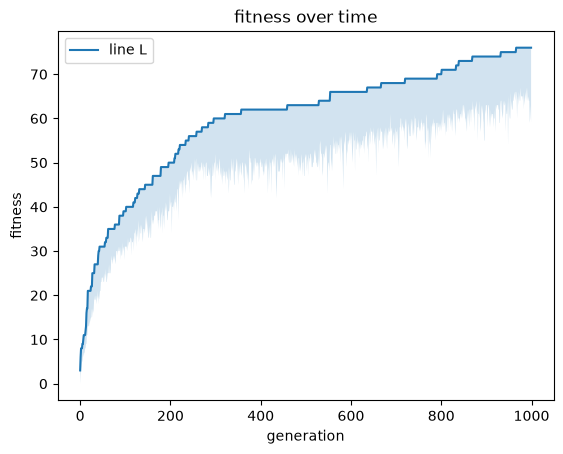

In [123]:
%pip install matplotlib
import matplotlib.pyplot as plt

x  = range(1000)
plt.plot(x, max_fitnesses, label="line L")
plt.fill_between(x, min_fitnesses, max_fitnesses, alpha=0.2)
plt.plot()

plt.xlabel("generation")
plt.ylabel("fitness")
plt.title("fitness over time")
plt.legend()
plt.show()

In [124]:
for i in range (5):
    pprint.PrettyPrinter(indent=2, depth=3).pprint(population[i])


{ 'fitness': 76,
  'ingredients': [ { 'amount': 5,
                     'cons': 'SOLID',
                     'flavour': 'none',
                     'is_indonesian': False,
                     'name': 'walnuts and pecans',
                     'source': 'Coconut Oatmeal Cookies',
                     'type': 'seeds_nuts_dried_fruits',
                     'unit': 'g'},
                   { 'amount': 5,
                     'cons': 'LIQUID',
                     'flavour': 'none',
                     'is_indonesian': False,
                     'name': 'canola oil',
                     'source': 'Chocolate Fudge Cookies',
                     'type': 'fats',
                     'unit': 'ml'},
                   { 'amount': 16,
                     'cons': 'SOLID',
                     'flavour': 'bitter',
                     'is_indonesian': False,
                     'name': 'ground coffee',
                     'source': 'Coconut Coffee with Ginger (Art and Kitchen)',
         